# SHAP Feature Analysis

## Overview
This notebook breaks open the black-box CatBoost model using SHAP (SHapley Additive exPlanations) values to interpret exactly what drives agricultural yields across India.

We load the **real production model (`CatBoost_best_final.cbm`)** and the 60-feature dataset to compute exact feature importance.

In [1]:
import pandas as pd
import numpy as np
from catboost import CatBoostRegressor, Pool
import shap
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
shap.initjs()

## 1. Load Model & Data
We load the production model and 1,000 random samples from the hold-out set to compute SHAP values (computing SHAP on the entire test set is highly computationally expensive).

In [2]:
X_test = pd.read_parquet('../checkpoints/X_test_cat.parquet')

model = CatBoostRegressor()
model.load_model('../models/CatBoost_best_final.cbm')

CATBOOST_CAT = ['season', 'crop', 'state_name', 'crop_season', 'state_crop', 'geo_cluster_10', 'geo_cluster_30', 'geo_cluster_50']

X_sample = X_test.sample(1000, random_state=42)
pool = Pool(X_sample, cat_features=CATBOOST_CAT)
print(f'Model loaded successfully with {len(model.feature_names_)} features.')

Model loaded successfully with 60 features.


## 2. Compute SHAP Values

In [3]:
explainer = shap.TreeExplainer(model)
shap_values = explainer(pool)

## 3. SHAP Summary Plot
This plot shows the global impact of features. Red indicates high feature values, and blue indicates low. Features at the top have the highest impact on yield predictions.

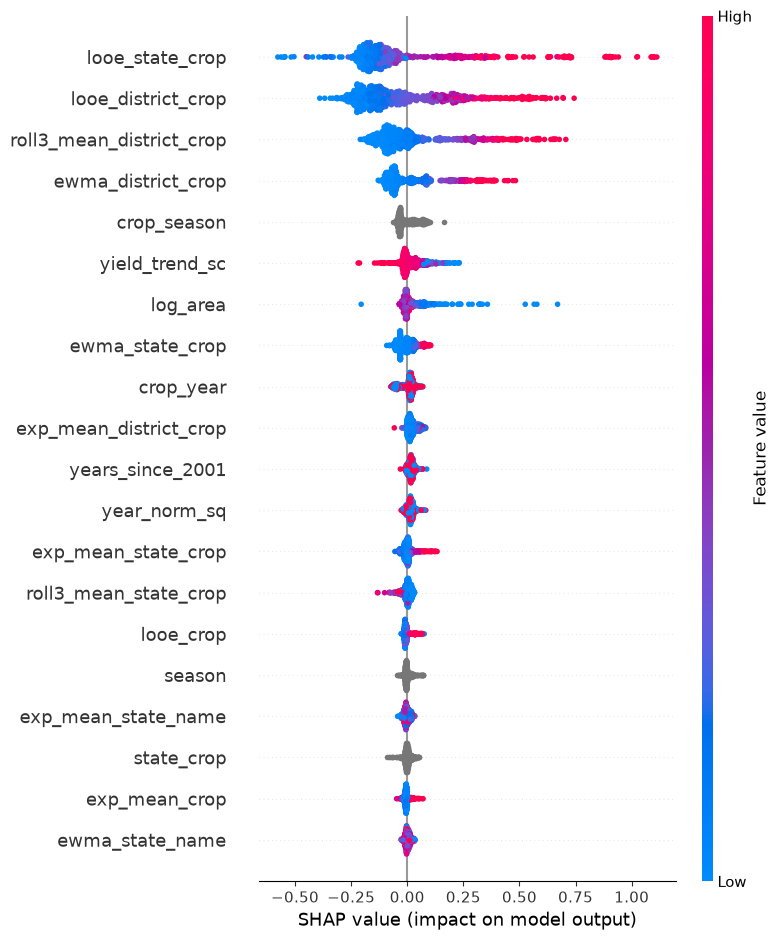

In [4]:
shap.summary_plot(shap_values, X_sample, show=False)
plt.tight_layout()
plt.show()

## 4. SHAP Feature Importance (Bar Plot)
This plot aggregates the absolute SHAP values to show the most important features on average.

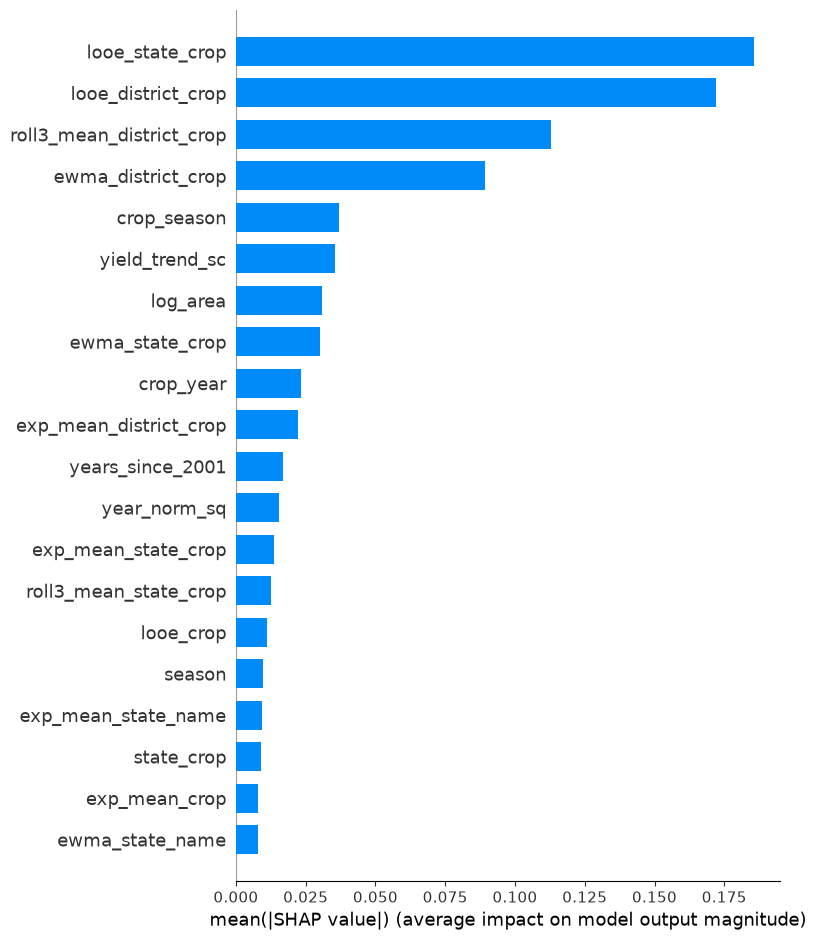

In [5]:
shap.summary_plot(shap_values, X_sample, plot_type='bar', show=False)
plt.tight_layout()
plt.show()

## 5. SHAP Waterfall Plot (Local Interpretation)
Let's analyze a single prediction to see exactly how the model arrived at its conclusion for a specific farm/season.

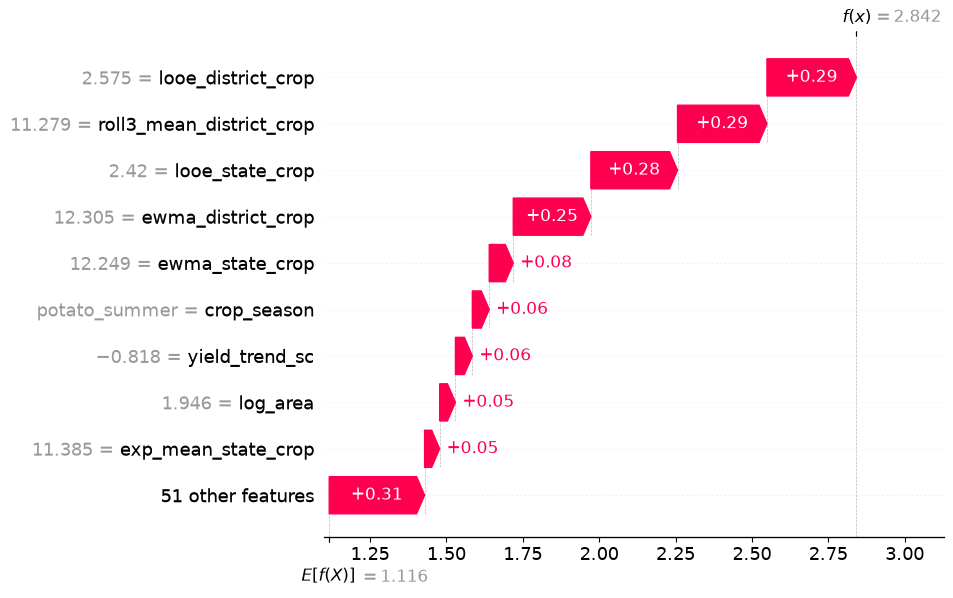

In [6]:
shap.waterfall_plot(shap.Explanation(values=shap_values[0].values, 
                                      base_values=shap_values[0].base_values, 
                                      data=X_sample.iloc[0], 
                                      feature_names=X_sample.columns))